# Multi-line emission cubes — HDF5 viewer

Run the cells from top to bottom using your **simba_env** kernel. Only the saved HDF5 output is needed; this notebook does not read the snapshot or rerun the pipeline.

- **PPP** arrays: `(z, y, x)`. Summing one spatial axis gives a projected luminosity map.
- **PPV** arrays: `(velocity, image_y, image_x)`. Summing velocity channels gives an integrated luminosity map.
- `cube_erg_s` already contains **luminosity per voxel**. Do **not** multiply by voxel volume or channel width when summing it.
- The default maps divide projected luminosity by physical pixel area: **erg s⁻¹ kpc⁻²**. This is intrinsic luminosity surface density, **not observed surface brightness or flux**.
- Zero-emission pixels are masked in gray on logarithmic maps; no artificial emission floor is added.

Change the controls below to select lines, choose a focus line, compare color scales, or export figures.


In [1]:
from pathlib import Path
import html
import math

import h5py
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
from IPython.display import display, HTML

DATA_FILE = Path("/Users/jiaheak/projects/Codex_SIMBA/output_line_cubes.hdf5")
LINES_TO_PLOT = None       # None = all saved lines; or a list of exact labels
FOCUS_LINE = None          # None = brightest selected line inside the cube
SHARED_LOG_SCALE = False   # True = identical color scale for all-line maps
SLICE_COORDINATE_KPC = 0.0 # PPP: nearest voxel center to this coordinate
EXPORT_DIR = None         # Or Path("/absolute/path/to/figure_folder")

plt.rcParams.update({"font.size": 10, "axes.titlesize": 11, "figure.dpi": 110})
MAP_UNIT = r"$\Sigma_L\ [\mathrm{erg\,s^{-1}\,kpc^{-2}}]$"
EMISSIVITY_UNIT = r"$\bar{\epsilon}\ [\mathrm{erg\,s^{-1}\,cm^{-3}}]$"


## 1. Inspect the file and check its geometry

Line labels are read from `lines/labels`; their order maps to `lines/line_0000`, `line_0001`, and so on. The checks below prevent transposed axes, missing lines, or incorrect units from producing misleading figures.


In [2]:
assert DATA_FILE.is_file(), f"File not found: {DATA_FILE}"
with h5py.File(DATA_FILE, "r") as saved:
    metadata = dict(saved.attrs)
    assert metadata.get("schema") == "codex_simba_line_cubes_v1", "Unsupported output schema."
    assert bool(metadata.get("complete", False)), "The saved run is incomplete."
    cube_type = metadata["cube_type"]
    assert cube_type in ("ppp", "ppv"), f"Unknown cube type: {cube_type}"
    all_labels = list(saved["lines/labels"].asstr()[...])
    assert len(all_labels) == metadata["line_count"] and len(set(all_labels)) == len(all_labels)
    group_paths = {label: f"lines/line_{index:04d}" for index, label in enumerate(all_labels)}
    axes = {name: dataset[...] for name, dataset in saved["axes"].items()}
    provenance = dict(saved["provenance"].attrs)
    center_kpc = saved["geometry/center_kpc"][...]
    if cube_type == "ppp":
        expected_order = "z,y,x"
        edge_names = ("x_edges_kpc", "y_edges_kpc", "z_edges_kpc")
        image_x_name, image_y_name = "x", "y"
        voxel_volume = saved["geometry/voxel_volume_cm3"][...]
        assert saved["geometry/voxel_volume_cm3"].attrs["unit"] == "cm^3"
    else:
        expected_order = "velocity,y,x"
        edge_names = ("image_x_edges_kpc", "image_y_edges_kpc", "velocity_edges_kms")
        image_x_name, image_y_name = metadata["image_x_axis"], metadata["image_y_axis"]
        voxel_volume = None
    assert metadata["cube_axis_order"] == expected_order
    for name in edge_names:
        edge = axes[name]
        assert edge.ndim == 1 and edge.size >= 2 and np.all(np.isfinite(edge))
        assert np.all(np.diff(edge) > 0), f"Invalid edges: {name}"
        unit = "km s^-1" if name == "velocity_edges_kms" else "kpc"
        assert saved[f"axes/{name}"].attrs["unit"] == unit
    x_edges, y_edges, third_edges = [axes[name] for name in edge_names]
    expected_shape = (len(third_edges) - 1, len(y_edges) - 1, len(x_edges) - 1)
    if voxel_volume is not None:
        assert voxel_volume.shape == expected_shape
        assert np.all(np.isfinite(voxel_volume)) and np.all(voxel_volume > 0)
    for label, path in group_paths.items():
        group = saved[path]
        assert group.attrs["line_label"] == label
        assert group["cube_erg_s"].shape == expected_shape
        assert group["cube_erg_s"].attrs["unit"] == "erg s^-1"
        assert group["cube_erg_s"].attrs["axis_order"] == expected_order

if LINES_TO_PLOT is None:
    selected_labels = list(all_labels)
else:
    assert isinstance(LINES_TO_PLOT, list) and LINES_TO_PLOT, "Supply a nonempty list of labels."
    assert len(set(LINES_TO_PLOT)) == len(LINES_TO_PLOT), "Repeated selected labels."
    missing = [label for label in LINES_TO_PLOT if label not in group_paths]
    assert not missing, f"Missing lines: {missing}; available: {all_labels}"
    selected_labels = list(LINES_TO_PLOT)

print(f"File: {DATA_FILE}")
print(f"Mode: {cube_type.upper()} | shape: {expected_shape} | array order: {expected_order}")
print(f"Saved lines: {len(all_labels)} | selected gas particles: {metadata['selected_particle_count']:,}")
print(f"Physical center [x,y,z] (kpc): {center_kpc}")
print(f"Map extent: {x_edges[0]:g} to {x_edges[-1]:g} kpc; "
      f"{y_edges[0]:g} to {y_edges[-1]:g} kpc")
print(f"Target: {provenance['group_type']} index {provenance['target_index']}")
if cube_type == "ppv":
    print(f"LOS axis: {metadata['los_axis']} | systemic velocity: {metadata['systemic_velocity_kms']:g} km/s")


File: /Users/jiaheak/projects/Codex_SIMBA/output_line_cubes.hdf5
Mode: PPP | shape: (100, 100, 100) | array order: z,y,x
Saved lines: 6 | selected gas particles: 2,377,715
Physical center [x,y,z] (kpc): [37422.70220588 45422.05882353 54819.74954044]
Map extent: -1600 to 1600 kpc; -1600 to 1600 kpc
Target: halo index 0


In [3]:
def load_cube(label):
    """Read one line at a time and check its luminosity values.

    Returns: cube (numpy.ndarray): finite, nonnegative luminosity per voxel.
    """
    with h5py.File(DATA_FILE, "r") as saved:
        cube = saved[f"{group_paths[label]}/cube_erg_s"][...]
    assert cube.shape == expected_shape and np.all(np.isfinite(cube))
    assert np.all(cube >= 0), f"Negative emission in {label}"
    return cube


def surface_luminosity(image, horizontal_edges, vertical_edges):
    """Convert projected luminosity per pixel into luminosity per physical area.

    Returns: surface (numpy.ndarray): projected luminosity in erg/s/kpc^2.
    """
    area_kpc2 = np.diff(vertical_edges)[:, None] * np.diff(horizontal_edges)[None, :]
    assert image.shape == area_kpc2.shape
    return image / area_kpc2


# Keep only 2D maps, 1D profiles, and summary numbers for all lines.
projected_maps, profiles, summary = {}, {}, []
for label in selected_labels:
    cube = load_cube(label)
    projected_maps[label] = surface_luminosity(cube.sum(axis=0), x_edges, y_edges)
    if cube_type == "ppv":
        profiles[label] = cube.sum(axis=(1, 2)) / np.diff(third_edges)
    with h5py.File(DATA_FILE, "r") as saved:
        info = dict(saved[group_paths[label]].attrs)
    total = float(cube.sum())
    np.testing.assert_allclose(total, info["included_luminosity_erg_s"], rtol=1e-10, atol=0)
    np.testing.assert_allclose(info["included_luminosity_erg_s"] + info["excluded_luminosity_erg_s"],
                               info["input_luminosity_erg_s"], rtol=1e-10, atol=0)
    assert info["included_particle_count"] + info["excluded_particle_count"] == info["input_particle_count"]
    if "clipped_particle_count" in info:
        assert 0 <= info["clipped_particle_count"] <= info["input_particle_count"]
    info.update(label=label, summed_luminosity=total,
                retained_fraction=total / info["input_luminosity_erg_s"]
                if info["input_luminosity_erg_s"] > 0 else np.nan)
    summary.append(info)
    del cube

if FOCUS_LINE is None:
    focus_line = max(summary, key=lambda row: row["summed_luminosity"])["label"]
    print(f"Focus line (brightest selected line in the cube): {focus_line}")
else:
    assert FOCUS_LINE in selected_labels, "FOCUS_LINE must be one of the selected labels."
    focus_line = FOCUS_LINE

rows = []
for row in summary:
    fraction = f"{100 * row['retained_fraction']:.2f}%" if np.isfinite(row["retained_fraction"]) else "undefined (zero input)"
    clipped = f"{row['clipped_particle_count']:,}" if "clipped_particle_count" in row else "not reported"
    rows.append("<tr>" + "".join(f"<td>{value}</td>" for value in (
        html.escape(row["label"]), f"{row['summed_luminosity']:.4e}", fraction,
        f"{row['excluded_particle_count']:,}", clipped)) + "</tr>")
display(HTML("<table><thead><tr><th>Exact line label</th><th>In-cube L (erg/s)</th>"
             "<th>Input luminosity retained</th><th>Excluded particles</th><th>Clipped particles</th>"
             "</tr></thead><tbody>" + "".join(rows) + "</tbody></table>"))
for model in sorted({row["abundance_model"] for row in summary if "abundance_model" in row}):
    print("Abundance assumption:", model)
print("Clipped particles were kept; the table boundary was used only for emissivity interpolation.")


Focus line (brightest selected line in the cube): O  8 18.9689A
Abundance assumption: fixed Cloudy default abundances
Clipped particles were kept; the table boundary was used only for emissivity interpolation.


Exact line label,In-cube L (erg/s),Input luminosity retained,Excluded particles,Clipped particles
O 7 21.6000A,2.5167e+40,92.60%,"37,528","8,195"
O 7 22.1000A,2.6462e+40,92.71%,"37,528","8,195"
O 8 18.9689A,1.8312e+42,96.65%,"37,528","8,195"
Ne 9 13.4500A,1.0007e+41,92.39%,"37,528","8,195"
Ne 9 13.7000A,9.7209e+40,92.43%,"37,528","8,195"
Ne10 12.1300A,8.7332e+41,97.01%,"37,528","8,195"


## 2. Integrated maps for all selected lines

For PPP these are projections along **z**; for PPV they integrate all saved velocity channels along the configured line of sight. Both include only gas inside the saved cube boundaries.

Color bars are independent by default, so equal colors across panels need not mean equal luminosity. Set `SHARED_LOG_SCALE = True` to compare absolute levels. The plotting helper uses the actual bin edges, including nonuniform grids.


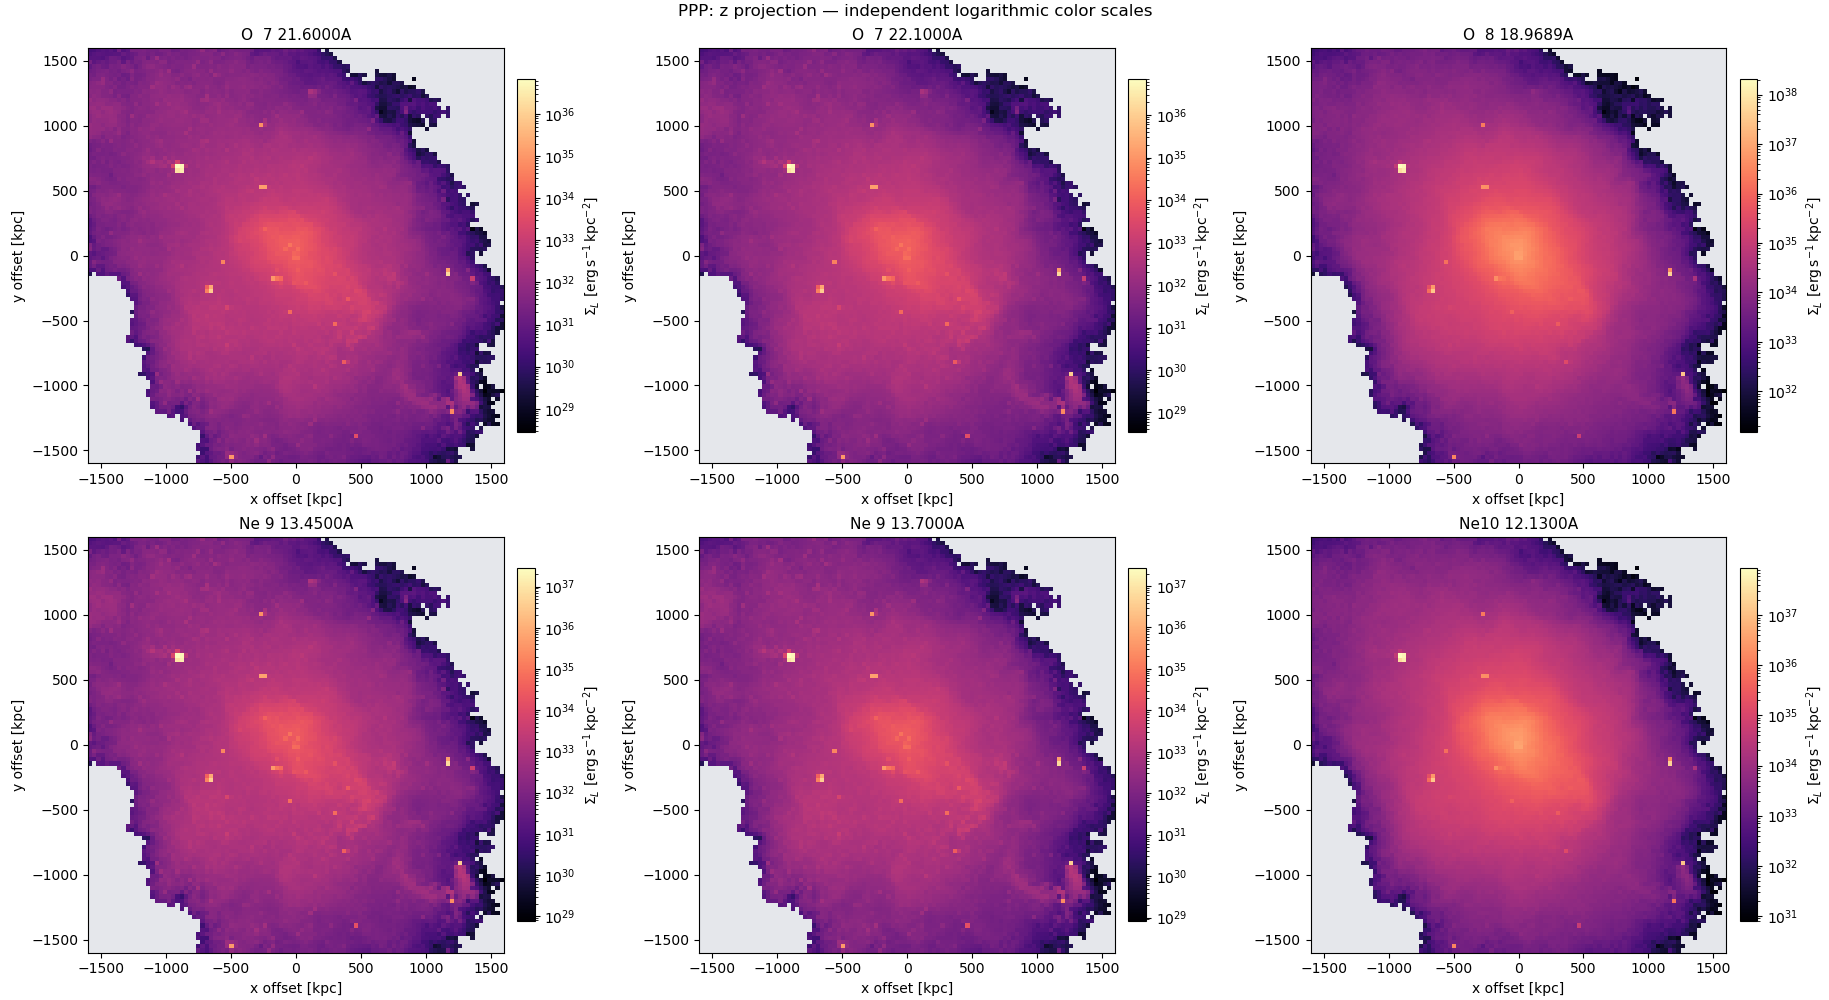

In [4]:
def logarithmic_norm(values):
    """Choose a logarithmic range using positive values, without adding a floor.

    Returns: norm (matplotlib.colors.LogNorm or None): None for zero-emission data.
    """
    positive = np.asarray(values)[np.asarray(values) > 0]
    if positive.size == 0:
        return None
    low, high = float(positive.min()), float(positive.max())
    if low == high:
        low, high = low / np.sqrt(10), high * np.sqrt(10)
    return LogNorm(vmin=low, vmax=high)


def draw_log_map(ax, values, horizontal_edges, vertical_edges, title,
                 horizontal_name, vertical_name, unit=MAP_UNIT, norm=None):
    """Draw a physical-coordinate map, explicitly marking empty emission.

    Returns: mesh (matplotlib.collections.QuadMesh): the plotted pixel data.
    """
    norm = norm if norm is not None else logarithmic_norm(values)
    cmap = plt.get_cmap("magma").copy()
    cmap.set_bad("#e5e7eb")
    mesh = ax.pcolormesh(horizontal_edges, vertical_edges, np.ma.masked_less_equal(values, 0),
                         shading="flat", cmap=cmap, norm=norm, rasterized=True)
    if norm is not None:
        ax.figure.colorbar(mesh, ax=ax, pad=0.02, shrink=0.85, label=unit)
    if not np.any(values > 0):
        ax.text(0.5, 0.5, "No positive emission", transform=ax.transAxes,
                ha="center", va="center", bbox=dict(facecolor="white", alpha=0.9))
    ax.set(title=title, xlabel=f"{horizontal_name} offset [kpc]", ylabel=f"{vertical_name} offset [kpc]")
    ax.set_aspect("equal")
    return mesh


def export_figure(fig, name):
    """Optionally save a PNG when EXPORT_DIR is explicitly enabled.

    Returns: none (NoneType): exports a figure or leaves disk contents unchanged.
    """
    if EXPORT_DIR is not None:
        directory = Path(EXPORT_DIR)
        directory.mkdir(parents=True, exist_ok=True)
        fig.savefig(directory / f"{name}.png", dpi=180, bbox_inches="tight")


common_norm = logarithmic_norm(np.concatenate([image.ravel() for image in projected_maps.values()])) if SHARED_LOG_SCALE else None
ncols = min(3, len(selected_labels))
nrows = math.ceil(len(selected_labels) / ncols)
fig, panels = plt.subplots(nrows, ncols, figsize=(6.1 * ncols, 5.0 * nrows),
                           squeeze=False, constrained_layout=True)
for ax, label in zip(panels.flat, selected_labels):
    draw_log_map(ax, projected_maps[label], x_edges, y_edges, label,
                 image_x_name, image_y_name, norm=common_norm)
for ax in list(panels.flat)[len(selected_labels):]:
    ax.set_visible(False)
view_name = "z projection" if cube_type == "ppp" else "velocity-integrated map"
fig.suptitle(f"{cube_type.upper()}: {view_name} — " +
             ("shared" if SHARED_LOG_SCALE else "independent") + " logarithmic color scales")
export_figure(fig, "all_line_maps")
plt.show()


## 3. Total luminosity and aperture coverage

These totals refer to the saved aperture, not the entire halo. The retained fraction compares in-cube luminosity with the luminosity of all gas passed to the cube builder. It does not measure the fraction of all simulation gas selected as CGM.


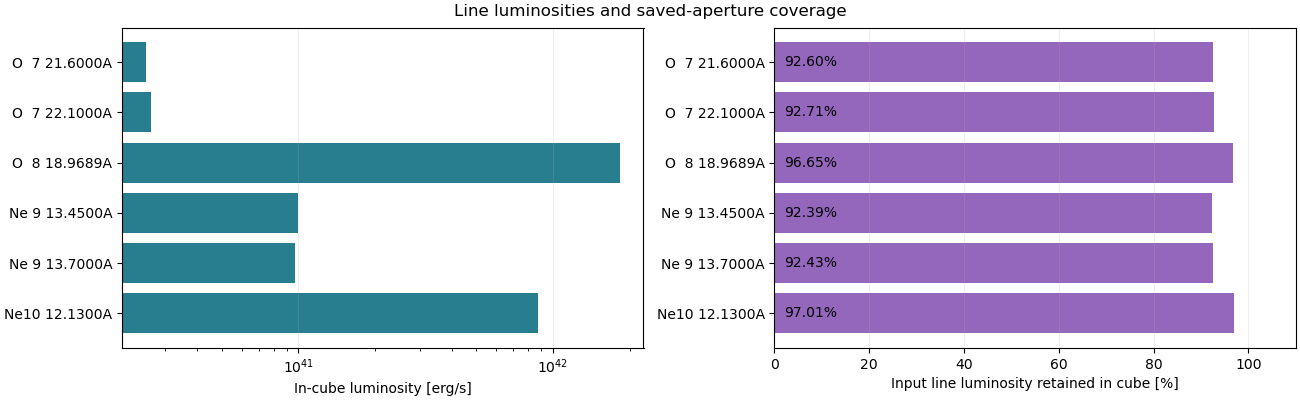

In [5]:
luminosities = np.array([row["summed_luminosity"] for row in summary])
fractions = np.array([row["retained_fraction"] for row in summary])
positions = np.arange(len(summary))
fig, panels = plt.subplots(1, 2, figsize=(13, max(4, 0.55 * len(summary))), constrained_layout=True)
panels[0].barh(positions, luminosities, color="#287d8e")
panels[0].set(yticks=positions, yticklabels=selected_labels, xlabel="In-cube luminosity [erg/s]")
if np.any(luminosities > 0):
    panels[0].set_xscale("log")
for i, value in enumerate(luminosities):
    if value == 0:
        panels[0].text(0.02, i, "zero", transform=panels[0].get_yaxis_transform(), va="center")
panels[1].barh(positions, np.nan_to_num(fractions, nan=0) * 100, color="#9467bd")
panels[1].set(yticks=positions, yticklabels=selected_labels, xlim=(0, 110),
              xlabel="Input line luminosity retained in cube [%]")
for i, fraction in enumerate(fractions):
    label = f"{100 * fraction:.2f}%" if np.isfinite(fraction) else "undefined"
    panels[1].text(2, i, label, va="center", color="black")
for ax in panels:
    ax.invert_yaxis()
    ax.grid(axis="x", alpha=0.2)
fig.suptitle("Line luminosities and saved-aperture coverage")
export_figure(fig, "luminosity_and_coverage")
plt.show()


## 4. Inspect one line: projections or channel maps

For PPP, each panel integrates a different spatial axis. For PPV, channels are divided into up to three consecutive bands; each panel sums complete channels and reports the actual band edges. No interpolation between channels is performed.


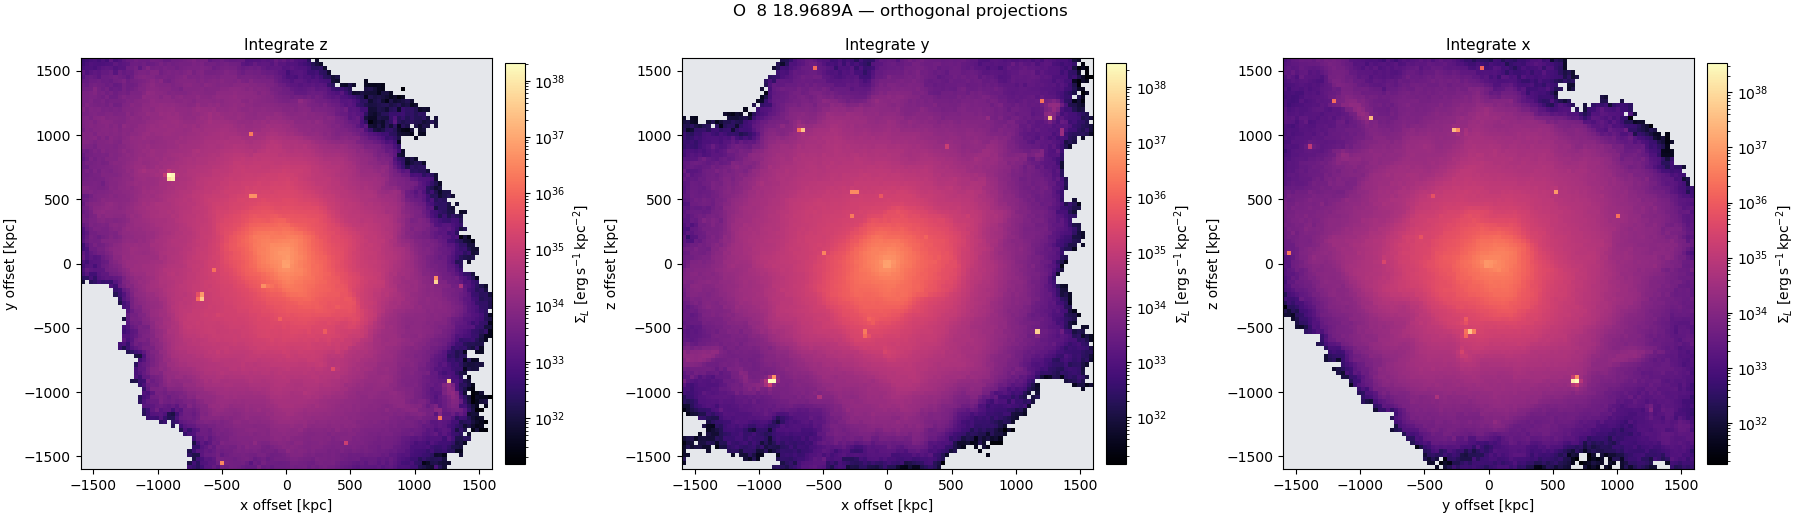

In [6]:
focus_cube = load_cube(focus_line)
fig, panels = plt.subplots(1, 3, figsize=(18, 5.2), constrained_layout=True)
if cube_type == "ppp":
    x, y, z = axes["x_edges_kpc"], axes["y_edges_kpc"], axes["z_edges_kpc"]
    projections = [
        (focus_cube.sum(axis=0), x, y, "x", "y", "Integrate z"),
        (focus_cube.sum(axis=1), x, z, "x", "z", "Integrate y"),
        (focus_cube.sum(axis=2), y, z, "y", "z", "Integrate x"),
    ]
    for ax, (image, horizontal, vertical, hname, vname, title) in zip(panels, projections):
        draw_log_map(ax, surface_luminosity(image, horizontal, vertical),
                     horizontal, vertical, title, hname, vname)
else:
    chunks = np.array_split(np.arange(focus_cube.shape[0]), min(3, focus_cube.shape[0]))
    for ax, indices in zip(panels, chunks):
        image = focus_cube[indices].sum(axis=0)
        title = f"{third_edges[indices[0]]:g} to {third_edges[indices[-1] + 1]:g} km/s"
        draw_log_map(ax, surface_luminosity(image, x_edges, y_edges),
                     x_edges, y_edges, title, image_x_name, image_y_name)
    for ax in panels[len(chunks):]:
        ax.set_visible(False)
fig.suptitle(focus_line + (" — orthogonal projections" if cube_type == "ppp" else " — velocity channel bands"))
export_figure(fig, "focus_projections_or_channels")
plt.show()


## 5. PPP emissivity slices / PPV line profiles

PPP slices use the saved **volume-averaged emissivity**, not luminosity per voxel. A slice is a single voxel layer, not a projection. The displayed coordinate is the nearest voxel center to `SLICE_COORDINATE_KPC`.

PPV spectra show **dL/dv = channel luminosity / channel width**, not luminosity per channel. Their integral over bin widths recovers the in-cube luminosity. No extra thermal or instrumental broadening is added here.


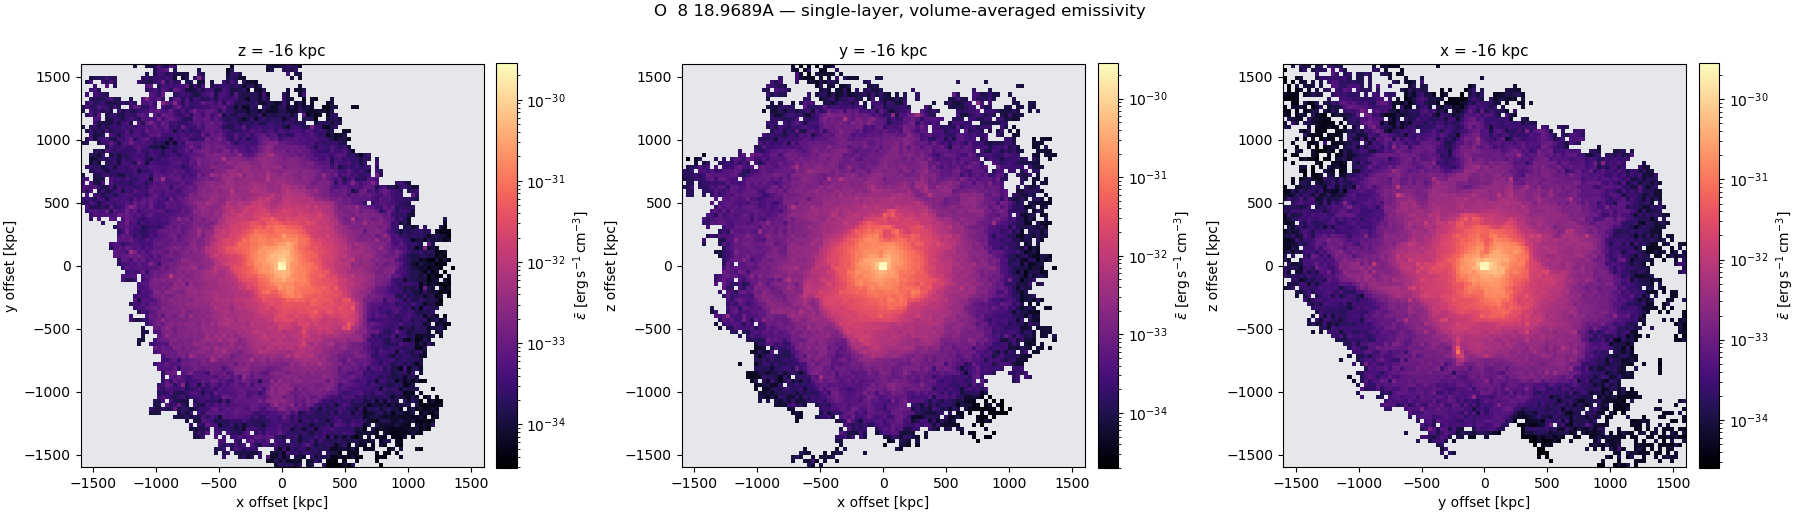

In [7]:
if cube_type == "ppp":
    with h5py.File(DATA_FILE, "r") as saved:
        dataset = saved[f"{group_paths[focus_line]}/volume_emissivity_erg_s_cm3"]
        assert dataset.attrs["unit"] == "erg s^-1 cm^-3"
        epsilon = dataset[...]
    assert epsilon.shape == focus_cube.shape and np.all(np.isfinite(epsilon)) and np.all(epsilon >= 0)
    np.testing.assert_allclose(epsilon * voxel_volume, focus_cube, rtol=1e-10, atol=0)
    centers = {name: (axes[f"{name}_edges_kpc"][:-1] + axes[f"{name}_edges_kpc"][1:]) / 2
               for name in ("x", "y", "z")}
    ix, iy, iz = [int(np.argmin(np.abs(centers[name] - SLICE_COORDINATE_KPC))) for name in ("x", "y", "z")]
    slices = [
        (epsilon[iz, :, :], x, y, "x", "y", f"z = {centers['z'][iz]:g} kpc"),
        (epsilon[:, iy, :], x, z, "x", "z", f"y = {centers['y'][iy]:g} kpc"),
        (epsilon[:, :, ix], y, z, "y", "z", f"x = {centers['x'][ix]:g} kpc"),
    ]
    fig, panels = plt.subplots(1, 3, figsize=(18, 5.2), constrained_layout=True)
    for ax, (image, horizontal, vertical, hname, vname, title) in zip(panels, slices):
        draw_log_map(ax, image, horizontal, vertical, title, hname, vname, unit=EMISSIVITY_UNIT)
    fig.suptitle(focus_line + " — single-layer, volume-averaged emissivity")
    export_figure(fig, "focus_emissivity_slices")
else:
    ncols = min(3, len(selected_labels))
    nrows = math.ceil(len(selected_labels) / ncols)
    fig, panels = plt.subplots(nrows, ncols, figsize=(5.6 * ncols, 3.7 * nrows),
                               squeeze=False, constrained_layout=True)
    for ax, label in zip(panels.flat, selected_labels):
        density = profiles[label]
        np.testing.assert_allclose(np.sum(density * np.diff(third_edges)),
                                   next(row["summed_luminosity"] for row in summary if row["label"] == label),
                                   rtol=1e-10, atol=0)
        ax.stairs(density, third_edges, color="#287d8e")
        if np.any(density > 0):
            ax.set_yscale("log")
        else:
            ax.text(0.5, 0.5, "No emission", ha="center", transform=ax.transAxes)
        ax.set(title=label, xlabel="LOS velocity relative to systemic [km/s]",
               ylabel=r"$dL/dv\ [\mathrm{erg\,s^{-1}\,(km\,s^{-1})^{-1}}]$")
        ax.grid(alpha=0.2)
    for ax in list(panels.flat)[len(selected_labels):]:
        ax.set_visible(False)
    fig.suptitle("Spatially integrated line profiles")
    export_figure(fig, "all_line_profiles")
plt.show()


## 6. PPP spatial profiles / PPV velocity moments

Spatial profiles are **dL/dx**, **dL/dy**, and **dL/dz** after integrating the other two axes. PPV velocity moments are luminosity-weighted estimates from channel centers; they do not recover unresolved sub-channel velocities. Empty pixels are masked, not assigned a physical velocity of zero.


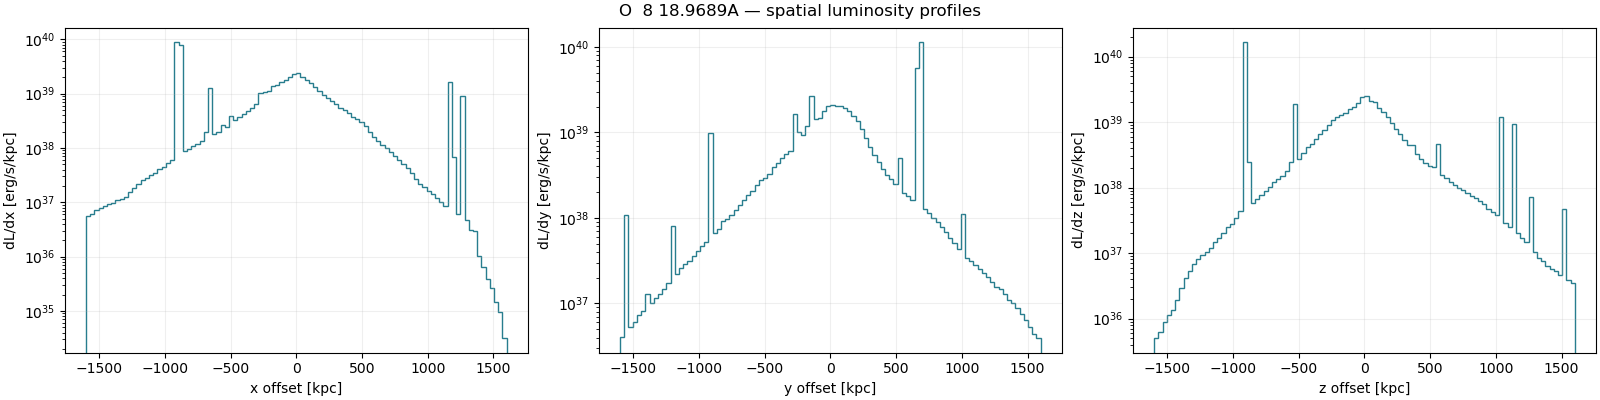

In [8]:
if cube_type == "ppp":
    fig, panels = plt.subplots(1, 3, figsize=(16, 4), constrained_layout=True)
    for ax, name, summed_axes in zip(panels, ("x", "y", "z"), ((0, 1), (0, 2), (1, 2))):
        edge = axes[f"{name}_edges_kpc"]
        luminosity_per_bin = focus_cube.sum(axis=summed_axes)
        density = luminosity_per_bin / np.diff(edge)
        np.testing.assert_allclose(np.sum(density * np.diff(edge)), focus_cube.sum(), rtol=1e-10, atol=0)
        ax.stairs(density, edge, color="#287d8e")
        if np.any(density > 0):
            ax.set_yscale("log")
        ax.set(xlabel=f"{name} offset [kpc]", ylabel=f"dL/d{name} [erg/s/kpc]")
        ax.grid(alpha=0.2)
    fig.suptitle(focus_line + " — spatial luminosity profiles")
    export_figure(fig, "focus_spatial_profiles")
else:
    velocity_centers = (third_edges[:-1] + third_edges[1:]) / 2
    weight = focus_cube.sum(axis=0)
    mean_velocity = np.divide((focus_cube * velocity_centers[:, None, None]).sum(axis=0), weight,
                              out=np.full(weight.shape, np.nan), where=weight > 0)
    variance_numerator = (focus_cube * (velocity_centers[:, None, None] - mean_velocity[None, :, :])**2).sum(axis=0)
    dispersion = np.sqrt(np.divide(variance_numerator, weight, out=np.full(weight.shape, np.nan), where=weight > 0))
    fig, panels = plt.subplots(1, 2, figsize=(13, 5.2), constrained_layout=True)
    velocity_limit = float(np.max(np.abs(third_edges)))
    finite_sigma = dispersion[np.isfinite(dispersion)]
    sigma_limit = float(finite_sigma.max()) if finite_sigma.size and finite_sigma.max() > 0 else 1.0
    for ax, image, title, cmap_name, low, high in (
        (panels[0], mean_velocity, "Luminosity-weighted mean velocity", "coolwarm", -velocity_limit, velocity_limit),
        (panels[1], dispersion, "Luminosity-weighted velocity dispersion", "viridis", 0, sigma_limit),
    ):
        cmap = plt.get_cmap(cmap_name).copy()
        cmap.set_bad("#e5e7eb")
        mesh = ax.pcolormesh(x_edges, y_edges, np.ma.masked_invalid(image), cmap=cmap,
                             vmin=low, vmax=high, shading="flat", rasterized=True)
        fig.colorbar(mesh, ax=ax, label="km/s", shrink=0.85)
        ax.set(title=title, xlabel=f"{image_x_name} offset [kpc]", ylabel=f"{image_y_name} offset [kpc]")
        ax.set_aspect("equal")
        if not np.any(np.isfinite(image)):
            ax.text(0.5, 0.5, "No emission", ha="center", transform=ax.transAxes)
    fig.suptitle(focus_line + " — channel-center velocity moments")
    export_figure(fig, "focus_velocity_moments")
plt.show()


### Interpretation limits

These are intrinsic, point-deposited emission products. Their appearance depends on the spatial/velocity bins and saved aperture; no smoothing, dust attenuation, cosmological dimming, instrument response, or noise is introduced by this notebook. The saved Cloudy abundance assumptions and boundary-clipping counts are shown above.

For another file, change `DATA_FILE` and rerun all cells. For another line, set `FOCUS_LINE` to an exact saved label. Figures are exported only when `EXPORT_DIR` is set.
